# Kmeans algorithm:

In [74]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
%matplotlib inline

In [75]:
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

In [76]:
RANDOM_STATE = 0

feat_cols = ["Age", "FollowersCount", "PostsCount", "EngagementRate"]

# 1) Load data
# -------------------------
df = pd.read_csv("rawData.csv", delimiter=",")
print("Shape:", df.shape)
display(df.head())

Shape: (200, 5)


,UserID,Age,FollowersCount,PostsCount,EngagementRate
0,1,25,1200,85,0.45
1,2,34,500,30,0.15
2,3,19,4500,120,0.75
3,4,55,150,5,0.05
4,5,28,1500,70,0.55


### cleaning and preprocessing --> missing values imputed by mean and standard scaling:

In [77]:
# 2) Cleaning
# (to_numeric + impute mean)
df[feat_cols] = df[feat_cols].apply(pd.to_numeric, errors="coerce")

imputer = SimpleImputer(strategy="mean")
df[feat_cols] = imputer.fit_transform(df[feat_cols])

print("Shape after cleaning:", df.shape)
display(df.head())

X = df[feat_cols].values
from sklearn.preprocessing import StandardScaler
Clus_dataSet = StandardScaler().fit_transform(X)

Shape after cleaning: (200, 5)


,UserID,Age,FollowersCount,PostsCount,EngagementRate
0,1,25.0,1200.0,85.0,0.45
1,2,34.0,500.0,30.0,0.15
2,3,19.0,4500.0,120.0,0.75
3,4,55.0,150.0,5.0,0.05
4,5,28.0,1500.0,70.0,0.55


C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMe

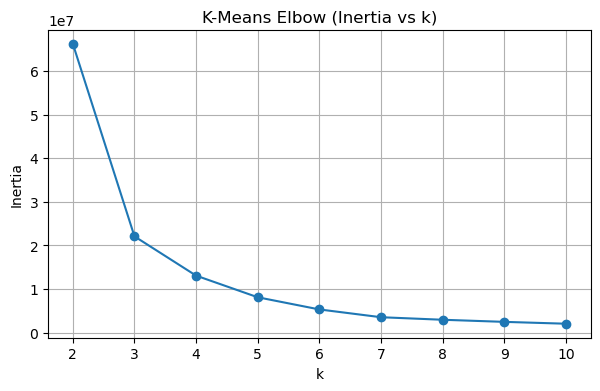

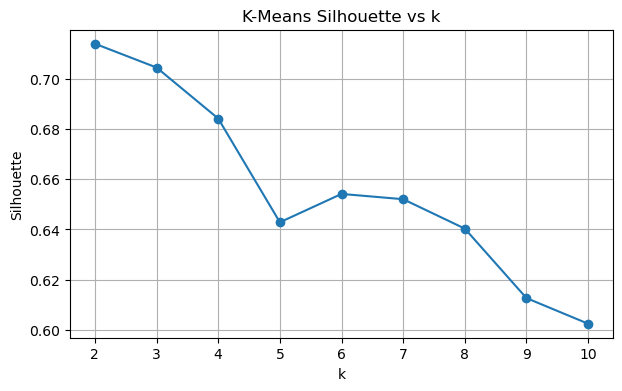

In [78]:
# -------------------------
# 3) Parameter Optimization
# Elbow + Silhouette for k
# -------------------------
k_range = range(2, 11)
inertias = []
silhs = []
models = {}

for k in k_range:
    km = KMeans(init="k-means++", n_clusters=k, n_init=12, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhs.append(silhouette_score(X, labels))
    models[k] = km

# Elbow plot
plt.figure(figsize=(7,4))
plt.plot(list(k_range), inertias, marker="o")
plt.title("K-Means Elbow (Inertia vs k)")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# Silhouette plot
plt.figure(figsize=(7,4))
plt.plot(list(k_range), silhs, marker="o")
plt.title("K-Means Silhouette vs k")
plt.xlabel("k")
plt.ylabel("Silhouette")
plt.grid(True)
plt.show()


### graph analysing:
<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif;">
  <p style="margin: 0;">
    با توجه به نتایج بهینه‌سازی، اگرچه مقدار شاخص سیلوئت در <b>k=2</b> کمی بالاتر است، اما اختلاف سیلوئت بین <b>k=2</b> و <b>k=3</b> زیاد نیست و هر دو حالت کیفیت قابل قبولی از نظر جدایی و فشردگی خوشه‌ها ارائه می‌دهند. در مقابل، نمودار <b>Elbow</b> نشان می‌دهد کاهش <span dir="ltr" style="unicode-bidi: bidi-override;"><i>Inertia</i></span> تا <b>k=3</b> بسیار چشمگیر است و پس از آن شیب کاهش کندتر می‌شود؛ بنابراین <b>k=3</b> نقطه‌ای است که با افزودن یک خوشه نسبت به <b>k=2</b>، بهبود معنی‌دار در کاهش پراکندگی درون‌خوشه‌ای به دست می‌آید، بدون اینکه کیفیت خوشه‌بندی از نظر سیلوئت به‌صورت محسوسی افت کند. به همین دلیل، برای دستیابی به سگمنت‌بندی دقیق‌تر و قابل تفسیرتر کاربران، مقدار <b>k=3</b> به‌عنوان تعداد خوشه‌های نهایی انتخاب می‌شود.
  </p>
</div>

## Fit final model and evaluation:
### silhouette metrics is 0.7 near to 1

In [79]:
# 4) Fit final model
best_k = 3
kmeans = models[best_k]
labels = kmeans.predict(X)

# -------------------------
# 5) Evaluation
# -------------------------
sil = silhouette_score(X, labels)
dbi = davies_bouldin_score(X, labels)
chi = calinski_harabasz_score(X, labels)

print("\nEvaluation Metrics (KMeans):")
print("Silhouette:", sil)
print("Davies-Bouldin:", dbi)
print("Calinski-Harabasz:", chi)

# -------------------------
# 6) Attach labels
# -------------------------
out = df.copy()
out["cluster_"] = labels

print("\nCluster sizes:")
print(out["cluster_"].value_counts().sort_index())


Evaluation Metrics (KMeans):
Silhouette: 0.7043751465197358
Davies-Bouldin: 0.3902888017971675
Calinski-Harabasz: 1334.504810683465

Cluster sizes:
cluster_
0     50
1    101
2     49
Name: count, dtype: int64


## profiling clusters and answer project questions:

In [80]:
#  Profiling (Descriptive stats)

profile_desc = out.groupby("cluster_")[feat_cols].describe()
print("\nCluster descriptive stats:")
print(profile_desc)


profile_mean = out.groupby("cluster_")[feat_cols].mean()
print("\nCluster means:")
display(profile_mean)

# -------------------------
# Answer project questions
# -------------------------
# Q1: cluster with younger users & higher engagement
age_rank = profile_mean["Age"].rank()  # smaller -> younger
eng_rank = (-profile_mean["EngagementRate"]).rank()  # larger engagement -> smaller rank after minus
score_young_engaged = age_rank + eng_rank
young_high_eng_cluster = score_young_engaged.idxmin()

# Q2: cluster with highest avg followers
highest_followers_cluster = profile_mean["FollowersCount"].idxmax()

# Q3: users with PostsCount > 75 (find cluster distribution + list)
high_posts = out[out["PostsCount"] > 75].copy()
high_posts_counts = high_posts["cluster_"].value_counts().sort_index()

print("\nQ1) Cluster with younger users AND higher engagement:", young_high_eng_cluster)
print("Q2) Cluster with highest avg FollowersCount:", highest_followers_cluster)

print("\nQ3) Users with PostsCount > 75:")
print("Count:", high_posts.shape[0])
print("Distribution across clusters:")
print(high_posts_counts)

if high_posts.shape[0] > 0:
    display(high_posts[["UserID", "PostsCount", "cluster_"]].sort_values(["cluster_", "PostsCount"], ascending=[True, False]).head(30))


Cluster descriptive stats:
            Age                                                     \
          count       mean       std   min   25%   50%   75%   max   
cluster_                                                             
0          50.0  24.760000  2.567934  19.0  23.0  25.0  27.0  29.0   
1         101.0  50.663366  8.536132  31.0  44.0  49.0  58.0  65.0   
2          49.0  32.102041  2.952717  25.0  30.0  32.0  35.0  38.0   

         FollowersCount               ... PostsCount        EngagementRate  \
                  count         mean  ...        75%    max          count   
cluster_                              ...                                    
0                  50.0  3348.000000  ...      130.0  140.0           50.0   
1                 101.0   365.029703  ...       41.0   60.0          101.0   
2                  49.0  1527.142857  ...       87.0   98.0           49.0   

                                                                
              mea

,Age,FollowersCount,PostsCount,EngagementRate
cluster_,,,,
0,24.760000,3348.000000,120.120000,0.768400
1,50.663366,365.029703,26.465347,0.142376
2,32.102041,1527.142857,80.244898,0.536327



Q1) Cluster with younger users AND higher engagement: 0
Q2) Cluster with highest avg FollowersCount: 0

Q3) Users with PostsCount > 75:
Count: 82
Distribution across clusters:
cluster_
0    50
2    32
Name: count, dtype: int64


,UserID,PostsCount,cluster_
17,18,140.0,0
113,114,139.0,0
49,50,138.0,0
153,154,137.0,0
109,110,136.0,0
29,30,135.0,0
149,150,135.0,0
93,94,134.0,0
173,174,133.0,0
53,54,132.0,0


## clusters decription:
<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif;">
  <p style="margin: 0 0 10px 0;">
    <b>کلاستر 0 (جوان‌های پرتعامل و پرنفوذ):</b>
    میانگین سن حدود <b>25</b> سال است و این گروه به‌طور متوسط بیشترین
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    را دارد (حدود <b>3348</b>). همچنین
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    بسیار بالا (میانگین <b>0.77</b>) و تعداد پست‌ها هم نسبتاً زیاد است.
    این خوشه نماینده‌ی کاربران جوان، فعال و اثرگذار (شبیه اینفلوئنسرها/اکانت‌های موفق) است.
  </p>

  <p style="margin: 0 0 10px 0;">
    <b>کلاستر 1 (میانسال‌های کم‌تعامل و کم‌نفوذ):</b>
    میانگین سن حدود <b>51</b> سال است و کمترین
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    را دارد (حدود <b>365</b>). 
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    خیلی پایین (میانگین <b>0.14</b>) و تعداد پست‌ها هم کمتر از بقیه است.
    این گروه بیشتر کاربران معمولی یا کم‌فعال هستند که تعامل و رشد پایینی دارند.
  </p>

  <p style="margin: 0;">
    <b>کلاستر 2 (بزرگسال‌های نسبتاً فعال با تعامل متوسط):</b>
    میانگین سن حدود <b>32</b> سال است و
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    در حد متوسط (حدود <b>1527</b>) قرار دارد. 
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    هم متوسط رو به بالا (میانگین <b>0.54</b>) و تعداد پست‌ها متوسط است.
    این خوشه کاربران بالغ‌تر و نسبتاً فعال را نشان می‌دهد که تعامل خوبی دارند ولی به اندازه خوشه 0 اثرگذار نیستند.
  </p>
</div>

## visualization

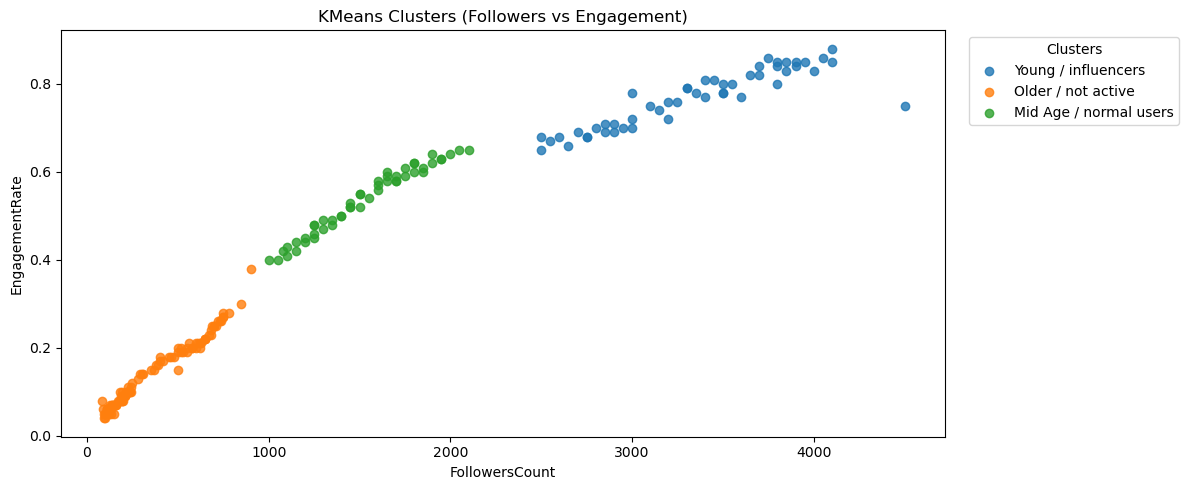

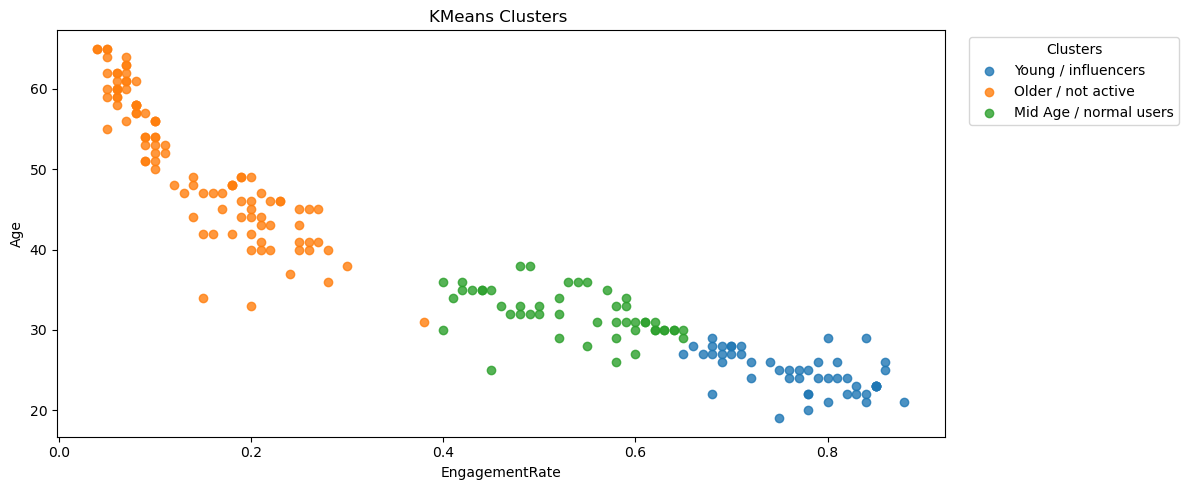

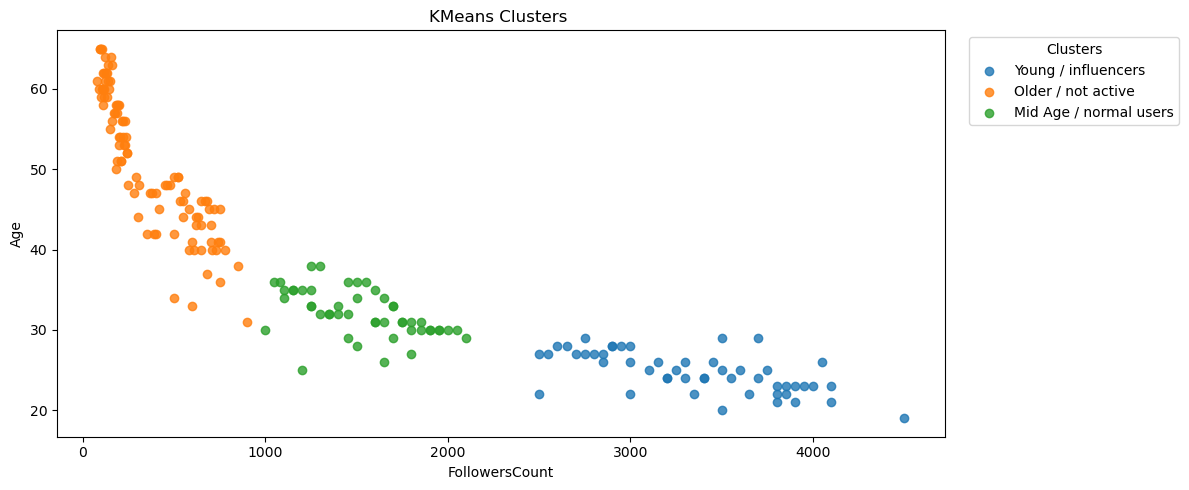

In [81]:
plt.figure(figsize=(12,5))
cluster_names = {
    0: "Young / influencers",
    1: "Older / not active",
    2: "Mid Age / normal users"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "FollowersCount"],
                out.loc[mask, "EngagementRate"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)

plt.xlabel("FollowersCount")
plt.ylabel("EngagementRate")
plt.title("KMeans Clusters (Followers vs Engagement)")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
cluster_names = {
    0: "Young / influencers",
    1: "Older / not active",
    2: "Mid Age / normal users"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "EngagementRate"],
                out.loc[mask, "Age"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)
plt.xlabel("EngagementRate")
plt.ylabel("Age")
plt.title("KMeans Clusters ")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
cluster_names = {
    0: "Young / influencers",
    1: "Older / not active",
    2: "Mid Age / normal users"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "FollowersCount"],
                out.loc[mask, "Age"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)
plt.xlabel("FollowersCount")
plt.ylabel("Age")
plt.title("KMeans Clusters ")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# HC algorithm:

In [82]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

display(df.head())

,UserID,Age,FollowersCount,PostsCount,EngagementRate
0,1,25.0,1200.0,85.0,0.45
1,2,34.0,500.0,30.0,0.15
2,3,19.0,4500.0,120.0,0.75
3,4,55.0,150.0,5.0,0.05
4,5,28.0,1500.0,70.0,0.55


## Scaling (MinMaxScaler)

In [83]:
X = df[feat_cols].values
min_max_scaler = MinMaxScaler()
X_norm = min_max_scaler.fit_transform(X)
print("X_norm sample:\n", X_norm[:5])

X_norm sample:
 [[0.13043478 0.25339367 0.59259259 0.48809524]
 [0.32608696 0.09502262 0.18518519 0.13095238]
 [0.         1.         0.85185185 0.8452381 ]
 [0.7826087  0.0158371  0.         0.01190476]
 [0.19565217 0.32126697 0.48148148 0.60714286]]


## Distance Matrix:

In [84]:
dist_matrix = euclidean_distances(X_norm, X_norm)
dist_matrix

array([[0.        , 0.5974052 , 0.87704084, ..., 0.39677521, 0.48861158,
        0.92797863],
       [0.5974052 , 0.        , 1.37111826, ..., 0.92253605, 0.2400842 ,
        0.43614811],
       [0.87704084, 1.37111826, 0.        , ..., 0.52068414, 1.24868055,
        1.6380817 ],
       ...,
       [0.39677521, 0.92253605, 0.52068414, ..., 0.        , 0.77612746,
        1.18675029],
       [0.48861158, 0.2400842 , 1.24868055, ..., 0.77612746, 0.        ,
        0.4412028 ],
       [0.92797863, 0.43614811, 1.6380817 , ..., 1.18675029, 0.4412028 ,
        0.        ]])

## Parameter Optimization (choose k by silhouette)

C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_agglomerative.py:588: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)
C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_agglomerative.py:588: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)
C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_agglomerative.py:588: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)
C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_agglomerative.py:588: ClusterWarning: The symmetric non-negative hollow observation matrix l

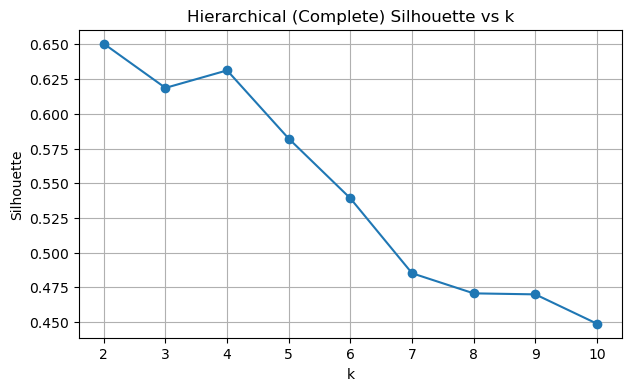

Best k: 2 | Best silhouette: 0.6504685753820115


In [85]:
k_range = range(2, 11)
silhs = []

for k in k_range:
    hc = AgglomerativeClustering(n_clusters=k, linkage="complete")
    labels_k = hc.fit_predict(dist_matrix)
    silhs.append(silhouette_score(X_norm, labels_k))

plt.figure(figsize=(7,4))
plt.plot(list(k_range), silhs, marker="o")
plt.title("Hierarchical (Complete) Silhouette vs k")
plt.xlabel("k")
plt.ylabel("Silhouette")
plt.grid(True)
plt.show()

best_k = list(k_range)[int(np.argmax(silhs))]
print("Best k:", best_k, "| Best silhouette:", max(silhs))

## Fit final model for k = 2 and evaluation with metrics

In [86]:
hc_final = AgglomerativeClustering(n_clusters=best_k, linkage="complete")
labels = hc_final.fit_predict(dist_matrix)

# Evaluation (on normalized features)

sil = silhouette_score(X_norm, labels)
dbi = davies_bouldin_score(X_norm, labels)
chi = calinski_harabasz_score(X_norm, labels)

print("\nEvaluation Metrics (Hierarchical):")
print("Silhouette:", sil)
print("Davies-Bouldin:", dbi)
print("Calinski-Harabasz:", chi)


Evaluation Metrics (Hierarchical):
Silhouette: 0.6504685753820115
Davies-Bouldin: 0.49899412634272877
Calinski-Harabasz: 639.5222005632811


C:\Users\Kian\anaconda3\envs\daproj\lib\site-packages\sklearn\cluster\_agglomerative.py:588: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  out = hierarchy.linkage(X, method=linkage, metric=affinity)


## Profiling (Descriptive stats)

In [87]:
out = df.copy()
out["cluster_"] = labels

print("\nCluster sizes:")
print(out["cluster_"].value_counts().sort_index())
profile_desc = out.groupby("cluster_")[feat_cols].describe()
print("\nCluster descriptive stats:")
display(profile_desc)

profile_mean = out.groupby("cluster_")[feat_cols].mean()
print("\nCluster means:")
display(profile_mean)


Cluster sizes:
cluster_
0    100
1    100
Name: count, dtype: int64

Cluster descriptive stats:


Age                                                FollowersCount  \
          count   mean       std   min   25%   50%   75%   max          count   
cluster_                                                                        
0         100.0  28.42  4.586277  19.0  25.0  28.0  32.0  38.0          100.0   
1         100.0  50.86  8.346075  33.0  44.0  49.5  58.0  65.0          100.0   

                   ... PostsCount        EngagementRate                    \
             mean  ...        75%    max          count    mean       std   
cluster_           ...                                                      
0         2431.30  ...      122.0  140.0          100.0  0.6508  0.138452   
1          359.68  ...       41.0   55.0          100.0  0.1400  0.073512   

                                           
           min     25%    50%   75%   max  
cluster_                                   
0         0.38  0.5475  0.650  0.78  0.88  
1         0.04  0.0700  0.115  0.20  0.30  

[2 rows x 32 columns]


Cluster means:


,Age,FollowersCount,PostsCount,EngagementRate
cluster_,,,,
0,28.42,2431.30,99.98,0.6508
1,50.86,359.68,26.13,0.1400


## clusters decription:
<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif;">
  <p style="margin: 0 0 10px 0;">
    <b>کلاستر 0 (جوان‌های پرتعامل و پرنفوذ):</b>
    میانگین سن حدود <b>28</b> سال است و این گروه به‌طور متوسط بیشترین
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    را دارد (حدود <b>2431</b>). همچنین
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    بسیار بالا (میانگین <b>0.65</b>) و تعداد پست‌ها هم نسبتاً زیاد است.
    این خوشه نماینده‌ی کاربران جوان، فعال و اثرگذار (شبیه اینفلوئنسرها/اکانت‌های موفق) است.
  </p>

  <p style="margin: 0 0 10px 0;">
    <b>کلاستر 1 (میانسال‌های کم‌تعامل و کم‌نفوذ):</b>
    میانگین سن حدود <b>51</b> سال است و کمترین
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    را دارد (حدود <b>360</b>). 
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    خیلی پایین (میانگین <b>0.14</b>) و تعداد پست‌ها هم کمتر از بقیه است.
    این گروه بیشتر کاربران معمولی یا کم‌فعال هستند که تعامل و رشد پایینی دارند.
  </p>
</div>


## Answer project questions


In [88]:
age_rank = profile_mean["Age"].rank()
eng_rank = (-profile_mean["EngagementRate"]).rank()
score_young_engaged = age_rank + eng_rank
young_high_eng_cluster = score_young_engaged.idxmin()

highest_followers_cluster = profile_mean["FollowersCount"].idxmax()

high_posts = out[out["PostsCount"] > 75].copy()
high_posts_counts = high_posts["cluster_"].value_counts().sort_index()

print("\nQ1) Cluster with younger users AND higher engagement:", young_high_eng_cluster)
print("Q2) Cluster with highest avg FollowersCount:", highest_followers_cluster)

print("\nQ3) Users with PostsCount > 75:")
print("Count:", high_posts.shape[0])
print("Distribution across clusters:")
print(high_posts_counts)

if high_posts.shape[0] > 0:
    display(high_posts[["UserID", "PostsCount", "cluster_"]].sort_values(["cluster_", "PostsCount"], ascending=[True, False]).head(30))


Q1) Cluster with younger users AND higher engagement: 0
Q2) Cluster with highest avg FollowersCount: 0

Q3) Users with PostsCount > 75:
Count: 82
Distribution across clusters:
cluster_
0    82
Name: count, dtype: int64


,UserID,PostsCount,cluster_
17,18,140.0,0
113,114,139.0,0
49,50,138.0,0
153,154,137.0,0
109,110,136.0,0
29,30,135.0,0
149,150,135.0,0
93,94,134.0,0
173,174,133.0,0
53,54,132.0,0


## visualization

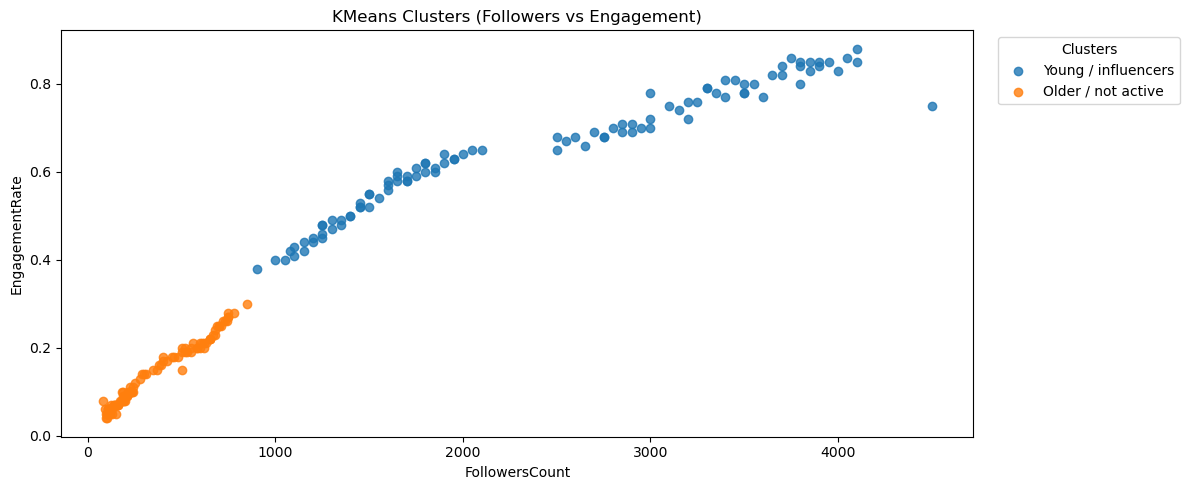

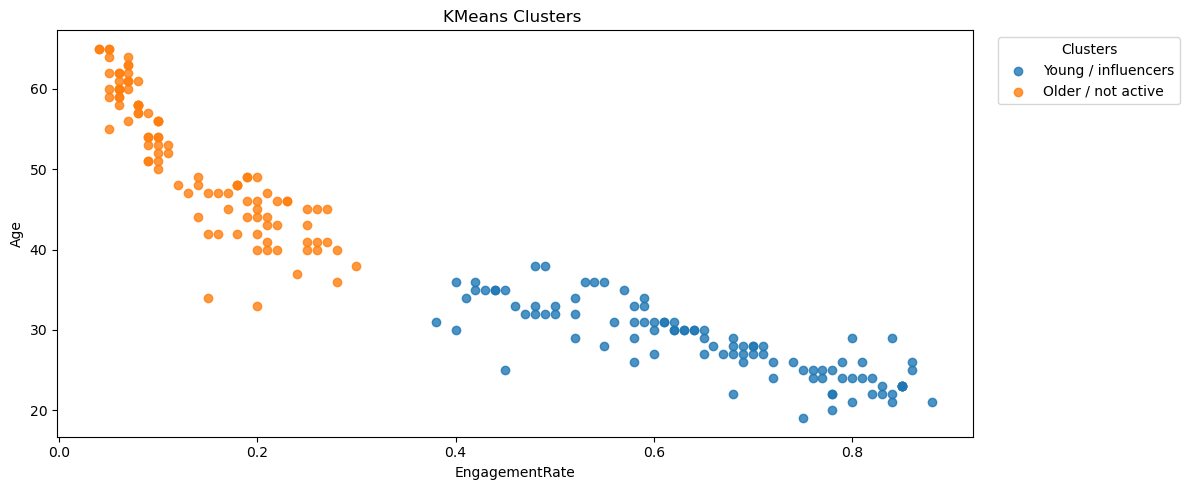

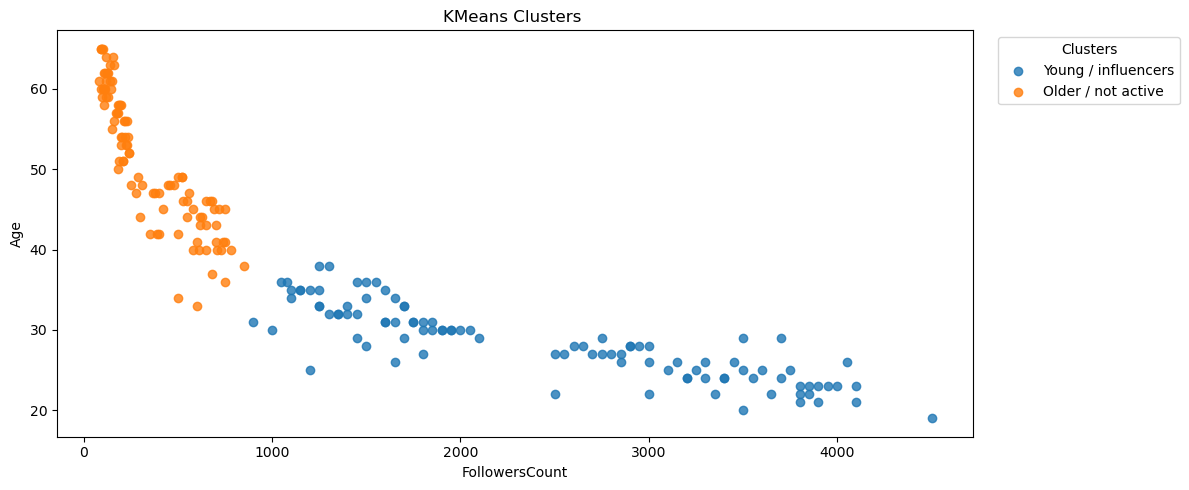

In [89]:
plt.figure(figsize=(12,5))
cluster_names = {
    0: "Young / influencers",
    1: "Older / not active",
    2: "Mid Age / normal users"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "FollowersCount"],
                out.loc[mask, "EngagementRate"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)

plt.xlabel("FollowersCount")
plt.ylabel("EngagementRate")
plt.title("KMeans Clusters (Followers vs Engagement)")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
cluster_names = {
    0: "Young / influencers",
    1: "Older / not active",
    2: "Mid Age / normal users"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "EngagementRate"],
                out.loc[mask, "Age"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)
plt.xlabel("EngagementRate")
plt.ylabel("Age")
plt.title("KMeans Clusters ")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
cluster_names = {
    0: "Young / influencers",
    1: "Older / not active",
    2: "Mid Age / normal users"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "FollowersCount"],
                out.loc[mask, "Age"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)
plt.xlabel("FollowersCount")
plt.ylabel("Age")
plt.title("KMeans Clusters ")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

C:\Users\Kian\AppData\Local\Temp\ipykernel_12696\2124073171.py:3: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  Z = hierarchy.linkage(dist_matrix ,'average')


[4 2 6 1 4 5 2 1 3 6 2 1 4 6 2 1 4 6 2 1 4 2 6 1 3 5 2 1 3 6 2 1 4 6 2 1 4
 5 2 1 4 6 2 1 4 6 2 1 4 6 2 1 4 6 2 1 3 5 2 1 4 6 2 1 4 5 2 1 3 6 2 1 4 6
 2 1 4 5 2 1 4 6 2 1 4 5 2 1 3 6 2 1 4 6 2 1 3 5 2 1 4 6 2 1 4 5 2 1 4 6 2
 1 4 6 2 1 3 6 2 1 4 6 2 1 4 6 2 1 4 6 2 1 4 5 2 1 4 5 2 1 4 6 2 1 4 6 2 1
 4 6 2 1 4 6 2 1 3 5 2 1 4 6 2 1 4 5 2 1 3 6 2 1 4 6 2 1 4 5 2 1 4 6 2 1 4
 5 2 1 3 6 2 1 4 6 2 1 3 5 2 1]


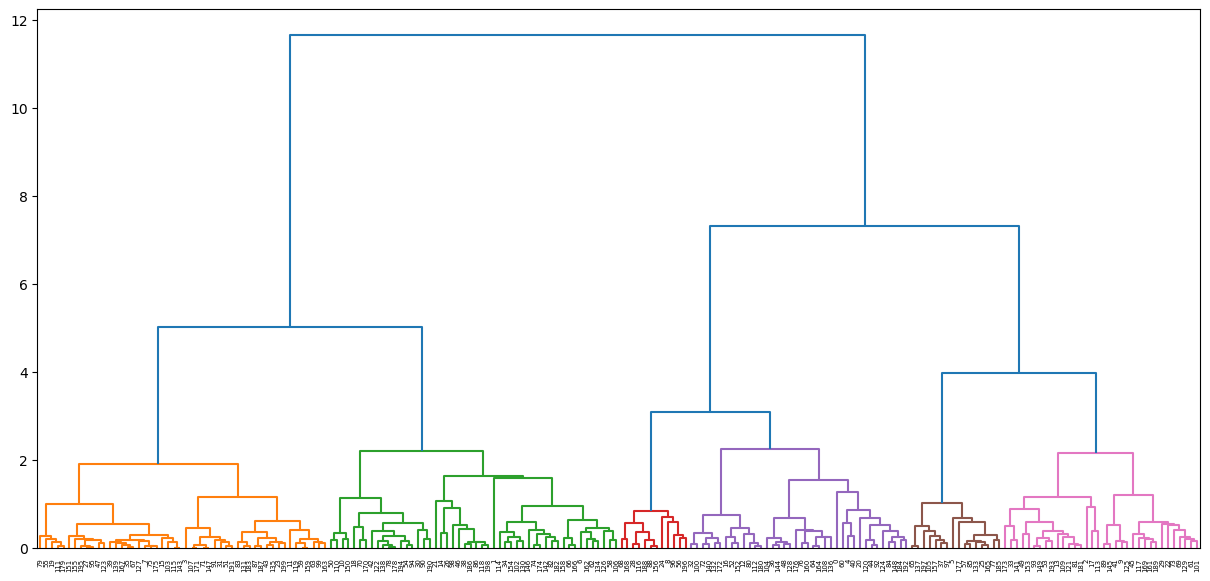

In [90]:
from scipy.cluster import hierarchy 
from scipy.spatial import distance_matrix
Z = hierarchy.linkage(dist_matrix ,'average')
clusters = hierarchy.fcluster(Z, t=3, criterion='distance')
print(clusters)
plt.figure(figsize=(15, 7))
dendro = hierarchy.dendrogram(Z, color_threshold=3)
plt.show()

# DBSCAN Algorithm:

In [91]:
# DBSCAN settings you can tune
min_samples = 5              
use_refinement = True        
percentile_for_eps = 95     

# refinement search range around eps_guess
refine_low = 0.7
refine_high = 1.3
refine_steps = 13

X = df[feat_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

 ## k-distance plot (similar style to typical DBSCAN notebook)

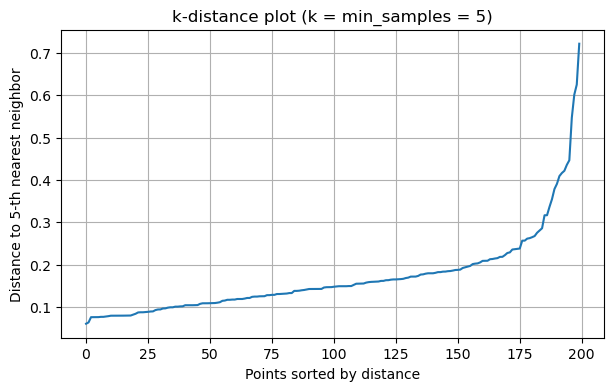

eps guess from 95th percentile of k-distance: 0.3792393696827269


In [92]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
k = int(min_samples)
neigh = NearestNeighbors(n_neighbors=k)
nbrs = neigh.fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

# distance to k-th nearest neighbor (k-distance)
k_distances = np.sort(distances[:, k-1])

plt.figure(figsize=(7,4))
plt.plot(k_distances)
plt.title(f"k-distance plot (k = min_samples = {k})")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {k}-th nearest neighbor")
plt.grid(True)
plt.show()

eps_guess = float(np.percentile(k_distances, percentile_for_eps))
print(f"eps guess from {percentile_for_eps}th percentile of k-distance:", eps_guess)

In [93]:
def eval_dbscan(Xs, labels):
    """Evaluate on non-noise points only; return metrics or NaN if not valid."""
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))

    sil = np.nan
    dbi = np.nan
    chi = np.nan

    if mask.sum() > 5 and len(set(labels[mask])) >= 2:
        X_eval = Xs[mask]
        y_eval = labels[mask]
        sil = silhouette_score(X_eval, y_eval)
        dbi = davies_bouldin_score(X_eval, y_eval)
        chi = calinski_harabasz_score(X_eval, y_eval)

    return n_clusters, n_noise, sil, dbi, chi

best_eps = eps_guess
best_labels = None
best_metrics = None

if not use_refinement:
    model = DBSCAN(eps=float(eps_guess), min_samples=int(min_samples))
    labels = model.fit_predict(X_scaled)
    best_labels = labels
    best_metrics = eval_dbscan(X_scaled, labels)

else:
    eps_candidates = np.round(np.linspace(eps_guess * refine_low, eps_guess * refine_high, refine_steps), 3)
    results = []
    best = None  # (sil, n_noise, eps, labels, n_clusters, dbi, chi)

    for eps in eps_candidates:
        model = DBSCAN(eps=float(eps), min_samples=int(min_samples))
        labels = model.fit_predict(X_scaled)

        n_clusters, n_noise, sil, dbi, chi = eval_dbscan(X_scaled, labels)
        results.append({
            "eps": float(eps),
            "min_samples": int(min_samples),
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "silhouette_non_noise": sil,
            "davies_bouldin_non_noise": dbi,
            "calinski_harabasz_non_noise": chi
        })

        # Choose best by highest silhouette; tie-breaker: fewer noise
        if not np.isnan(sil):
            if best is None or (sil > best[0]) or (np.isclose(sil, best[0]) and n_noise < best[1]):
                best = (sil, n_noise, eps, labels, n_clusters, dbi, chi)

    res_df = pd.DataFrame(results).sort_values(by="silhouette_non_noise", ascending=False)
    print("\nRefinement results (top 10):")
    display(res_df.head(10))

    if best is None:
        # Fallback to eps_guess if refinement didn't produce >=2 clusters
        print("Refinement failed to produce >=2 clusters (excluding noise). Falling back to eps_guess.")
        model = DBSCAN(eps=float(eps_guess), min_samples=int(min_samples))
        best_labels = model.fit_predict(X_scaled)
        best_eps = eps_guess
        best_metrics = eval_dbscan(X_scaled, best_labels)
    else:
        best_sil, best_noise, best_eps, best_labels, best_k, best_dbi, best_chi = best
        best_metrics = (best_k, best_noise, best_sil, best_dbi, best_chi)


Refinement results (top 10):


,eps,min_samples,n_clusters,n_noise,silhouette_non_noise,davies_bouldin_non_noise,calinski_harabasz_non_noise
10,0.455,5,2,3,0.647154,0.505108,618.232507
9,0.436,5,2,3,0.647154,0.505108,618.232507
12,0.493,5,2,2,0.645857,0.507130,616.002608
11,0.474,5,2,2,0.645857,0.507130,616.002608
1,0.284,5,3,10,0.624647,0.459561,736.408979
0,0.265,5,3,11,0.624124,0.459696,732.873324
3,0.322,5,3,8,0.622878,0.463881,736.207920
2,0.303,5,3,9,0.622546,0.462608,733.055642
4,0.341,5,3,6,0.622136,0.464770,746.543935
6,0.379,5,3,5,0.618149,0.466528,730.227001


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif;">
  <p style="margin: 0;">
    در کد <span dir="ltr" style="unicode-bidi: bidi-override;">DBSCAN</span> برای پیدا کردن هایپرپارامترهای بهینه، ابتدا مقدار 
    <span dir="ltr" style="unicode-bidi: bidi-override;">min_samples</span> را انتخاب می‌کنیم (مثلاً 5) و همان را به‌عنوان 
    <span dir="ltr" style="unicode-bidi: bidi-override;">k</span> در روش 
    <span dir="ltr" style="unicode-bidi: bidi-override;">k-distance</span> به کار می‌بریم؛ یعنی با 
    <span dir="ltr" style="unicode-bidi: bidi-override;">NearestNeighbors(n_neighbors=k)</span>
    برای هر نقطه فاصله‌ی آن تا <b>k‌-اُمین همسایه نزدیک</b> را محاسبه می‌کنیم، این فاصله‌ها را مرتب کرده و نمودار 
    <span dir="ltr" style="unicode-bidi: bidi-override;">k-distance</span> را رسم می‌کنیم تا محل «زانویی/شکست» نمودار مشخص شود (جایی که فاصله‌ها ناگهان افزایش پیدا می‌کنند). برای اینکه انتخاب 
    <span dir="ltr" style="unicode-bidi: bidi-override;">eps</span>
    فقط چشمی و سلیقه‌ای نباشد، در کد یک مقدار اولیه برای 
    <span dir="ltr" style="unicode-bidi: bidi-override;">eps</span>
    با استفاده از <b>صدک 95ام</b> این فاصله‌ها به‌عنوان 
    <span dir="ltr" style="unicode-bidi: bidi-override;">eps_guess</span>
    گرفته می‌شود؛ سپس (در حالت 
    <span dir="ltr" style="unicode-bidi: bidi-override;">refinement</span>)
    چند مقدار 
    <span dir="ltr" style="unicode-bidi: bidi-override;">eps</span>
    در بازه‌ای اطراف 
    <span dir="ltr" style="unicode-bidi: bidi-override;">eps_guess</span>
    (مثلاً از 0.7 تا 1.3 برابر آن) تست می‌شود و برای هر مقدار، الگوریتم اجرا شده و تعداد خوشه‌ها و تعداد نقاط نویز (برچسب 
    <span dir="ltr" style="unicode-bidi: bidi-override;">-1</span>) محاسبه می‌گردد. چون 
    <span dir="ltr" style="unicode-bidi: bidi-override;">DBSCAN</span>
    نویز تولید می‌کند، معیارهای کیفیت خوشه‌بندی مثل 
    <span dir="ltr" style="unicode-bidi: bidi-override;">Silhouette</span>،
    <span dir="ltr" style="unicode-bidi: bidi-override;">Davies–Bouldin</span>
    و
    <span dir="ltr" style="unicode-bidi: bidi-override;">Calinski–Harabasz</span>
    فقط روی نقاط <b>غیرنویز</b> محاسبه می‌شوند (و فقط وقتی حداقل دو خوشه واقعی وجود داشته باشد). در نهایت بهترین 
    <span dir="ltr" style="unicode-bidi: bidi-override;">eps</span>
    با معیار اصلی <b>بیشترین مقدار سیلوئت روی non-noise</b> انتخاب می‌شود و اگر چند گزینه نزدیک باشند، مدلی ترجیح داده می‌شود که <b>نویز کمتری</b> ایجاد کند؛ سپس همین پارامترهای منتخب برای تولید برچسب نهایی خوشه‌ها، پروفایلینگ، نمودارسازی و ذخیره خروجی استفاده می‌شوند.
  </p>
</div>

## Final DBSCAN output + evaluation

In [94]:
out = df.copy()
out["cluster_"] = best_labels

n_clusters, n_noise, sil, dbi, chi = best_metrics
print("\nFinal DBSCAN params:")
print("min_samples:", min_samples)
print("eps:", best_eps)

print("\nCluster stats:")
print("n_clusters (excluding noise):", n_clusters)
print("n_noise:", n_noise)

print("\nEvaluation metrics:")
print("Silhouette:", sil)
print("Davies-Bouldin:", dbi)
print("Calinski-Harabasz:", chi)

print("\nCluster sizes (including noise=-1):")
print(out["cluster_"].value_counts().sort_index())


Final DBSCAN params:
min_samples: 5
eps: 0.436

Cluster stats:
n_clusters (excluding noise): 2
n_noise: 3

Evaluation metrics:
Silhouette: 0.6471538781058097
Davies-Bouldin: 0.5051081551718389
Calinski-Harabasz: 618.2325071067037

Cluster sizes (including noise=-1):
cluster_
-1     3
 0    99
 1    98
Name: count, dtype: int64


## Cluster descriptive stats and means

In [95]:
print("\nCluster descriptive stats:")
display(out.groupby("cluster_")[feat_cols].describe())

cluster_means = out.groupby("cluster_")[feat_cols].mean()
cluster_medians = out.groupby("cluster_")[feat_cols].median()

print("\nCluster means:")
display(cluster_means)


Cluster descriptive stats:


Age                                                     \
         count       mean       std   min   25%   50%   75%   max   
cluster_                                                            
-1         3.0  26.000000  7.549834  19.0  22.0  25.0  29.5  34.0   
 0        99.0  51.030303  8.212055  33.0  44.5  50.0  58.0  65.0   
 1        98.0  28.551020  4.518285  20.0  25.0  28.5  32.0  38.0   

         FollowersCount               ... PostsCount        EngagementRate  \
                  count         mean  ...        75%    max          count   
cluster_                              ...                                    
-1                  3.0  2066.666667  ...      102.5  120.0            3.0   
 0                 99.0   358.262626  ...       41.0   55.0           99.0   
 1                 98.0  2422.755102  ...      122.0  140.0           98.0   

                                                            
              mean       std   min   25%   50%   75%   max  
cluster_                                                    
-1        0.450000  0.300000  0.15  0.30  0.45  0.60  0.75  
 0        0.139899  0.073879  0.04  0.07  0.11  0.20  0.30  
 1        0.651837  0.138008  0.38  0.55  0.65  0.78  0.88  

[3 rows x 32 columns]


Cluster means:


,Age,FollowersCount,PostsCount,EngagementRate
cluster_,,,,
-1,26.000000,2066.666667,78.333333,0.450000
0,51.030303,358.262626,26.090909,0.139899
1,28.551020,2422.755102,99.928571,0.651837


## clusters decription:
<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif;">
  <p style="margin: 0 0 10px 0;">
    <b>کلاستر 0 (میانسال‌های کم‌تعامل و کم‌نفوذ):</b>
    میانگین سن حدود <b>51</b> سال است و کمترین
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    را دارد (حدود <b>358</b>). 
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    خیلی پایین (میانگین <b>0.14</b>) و تعداد پست‌ها هم کمتر از بقیه است.
    این گروه بیشتر کاربران معمولی یا کم‌فعال هستند که تعامل و رشد پایینی دارند.
  </p>
    <p style="margin: 0 0 10px 0;">
    <b>کلاستر 1 (جوان‌های پرتعامل و پرنفوذ):</b>
    میانگین سن حدود <b>28</b> سال است و این گروه به‌طور متوسط بیشترین
    <span dir="ltr" style="unicode-bidi: bidi-override;">FollowersCount</span>
    را دارد (حدود <b>2422</b>). همچنین
    <span dir="ltr" style="unicode-bidi: bidi-override;">EngagementRate</span>
    بسیار بالا (میانگین <b>0.65</b>) و تعداد پست‌ها هم نسبتاً زیاد است.
    این خوشه نماینده‌ی کاربران جوان، فعال و اثرگذار (شبیه اینفلوئنسرها/اکانت‌های موفق) است.
  </p>
</div>

## Answer project questions

In [96]:
# Q1) Which cluster has younger users + higher engagement?
non_noise = out[out["cluster_"] != -1].copy()
if non_noise["cluster_"].nunique() >= 2:
    means_nn = non_noise.groupby("cluster_")[feat_cols].mean()
    age_rank = means_nn["Age"].rank()                      # smaller age => better
    eng_rank = (-means_nn["EngagementRate"]).rank()        # higher engagement => better
    young_high_eng_cluster = (age_rank + eng_rank).idxmin()
else:
    young_high_eng_cluster = None

# Q2) Which cluster has highest avg FollowersCount?
if non_noise["cluster_"].nunique() >= 1:
    highest_followers_cluster = non_noise.groupby("cluster_")["FollowersCount"].mean().idxmax()
else:
    highest_followers_cluster = None

# Q3) PostsCount > 75: are they in a specific cluster?
high_posts = out[out["PostsCount"] > 75].copy()
high_posts_dist = high_posts["cluster_"].value_counts().sort_index()

print("\nQ1) Cluster with younger users AND higher engagement:", young_high_eng_cluster)
print("Q2) Cluster with highest avg FollowersCount:", highest_followers_cluster)
print("\nQ3) Users with PostsCount > 75:")
print("Count:", high_posts.shape[0])
print("Distribution across clusters (incl noise):")
print(high_posts_dist)

if high_posts.shape[0] > 0:
    display(high_posts[["UserID", "PostsCount", "cluster_"]]
            .sort_values(["cluster_", "PostsCount"], ascending=[True, False])
            .head(30))


Q1) Cluster with younger users AND higher engagement: 1
Q2) Cluster with highest avg FollowersCount: 1

Q3) Users with PostsCount > 75:
Count: 82
Distribution across clusters (incl noise):
cluster_
-1     2
 1    80
Name: count, dtype: int64


,UserID,PostsCount,cluster_
2,3,120.0,-1
0,1,85.0,-1
17,18,140.0,1
113,114,139.0,1
49,50,138.0,1
153,154,137.0,1
109,110,136.0,1
29,30,135.0,1
149,150,135.0,1
93,94,134.0,1


## Visualization

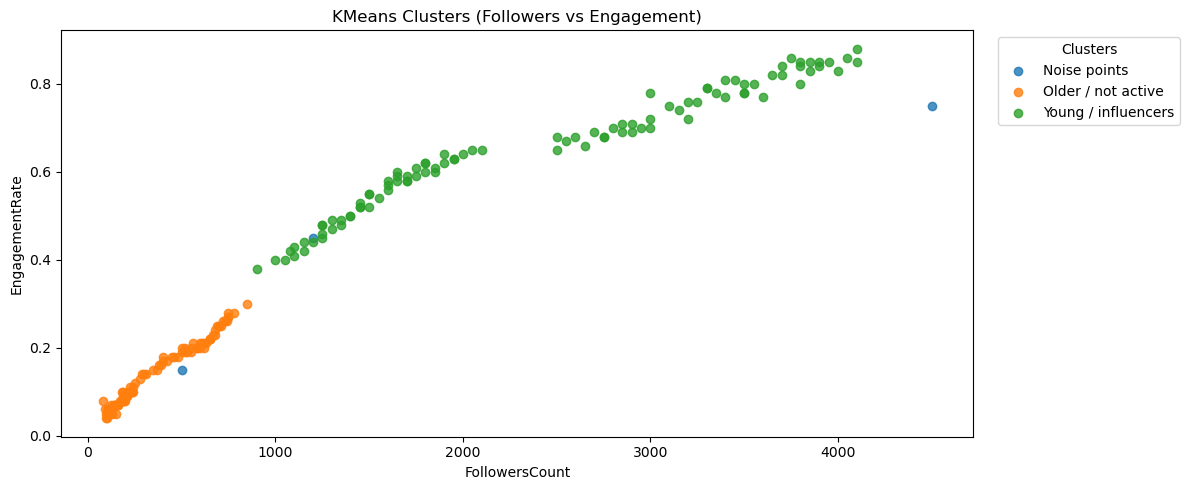

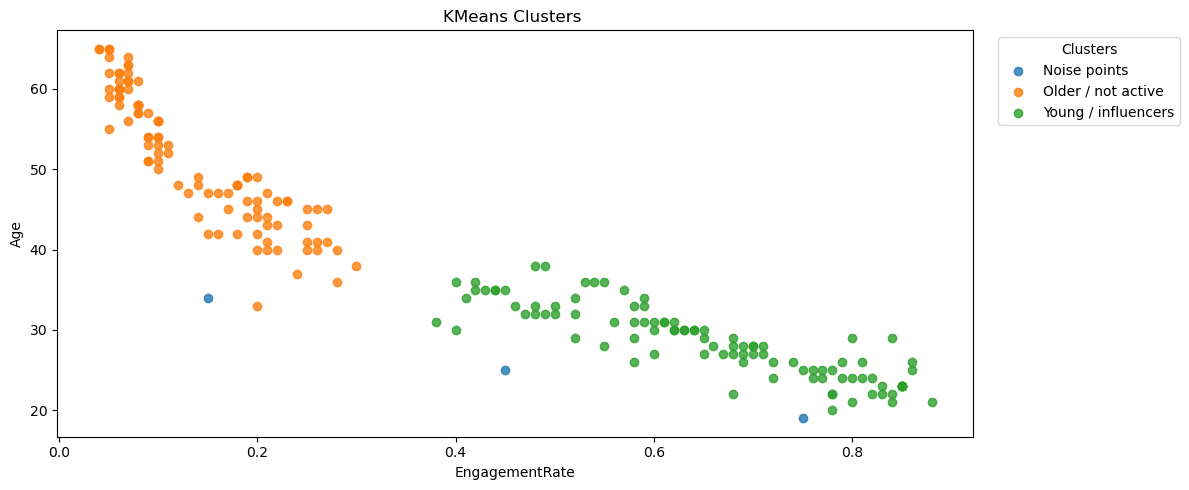

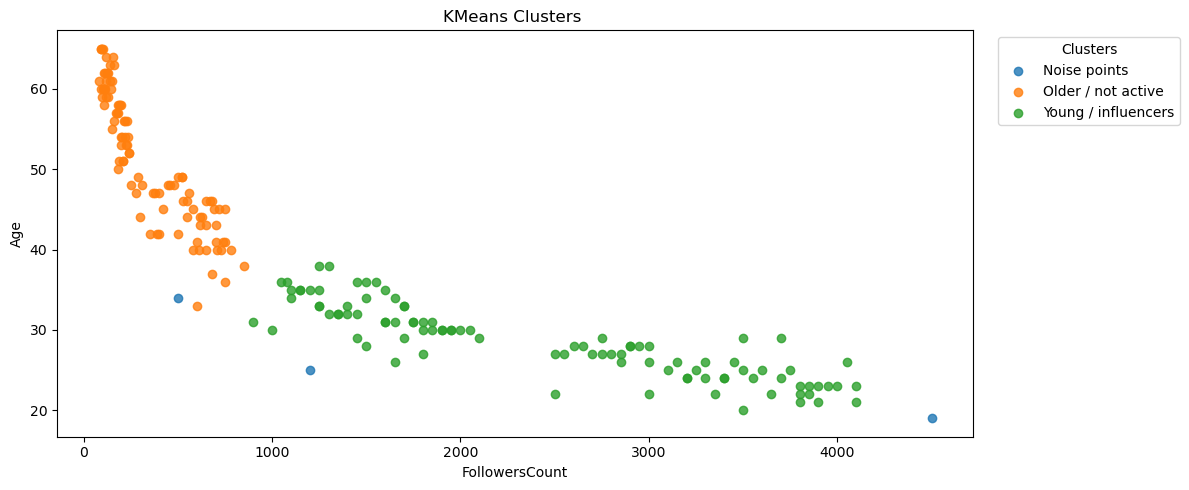

In [97]:
plt.figure(figsize=(12,5))
cluster_names = {
    1: "Young / influencers",
    0: "Older / not active",
    
    -1: "Noise points"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "FollowersCount"],
                out.loc[mask, "EngagementRate"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)

plt.xlabel("FollowersCount")
plt.ylabel("EngagementRate")
plt.title("KMeans Clusters (Followers vs Engagement)")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
cluster_names = {
    1: "Young / influencers",
    0: "Older / not active",
    
    -1: "Noise points"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "EngagementRate"],
                out.loc[mask, "Age"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)
plt.xlabel("EngagementRate")
plt.ylabel("Age")
plt.title("KMeans Clusters ")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
cluster_names = {
    1: "Young / influencers",
    0: "Older / not active",
    
    -1: "Noise points"
}

for cl in sorted(out["cluster_"].unique()):
    mask = out["cluster_"] == cl
    plt.scatter(out.loc[mask, "FollowersCount"],
                out.loc[mask, "Age"],
                label=cluster_names.get(cl, f"Cluster {cl}"),
                alpha=0.8)
plt.xlabel("FollowersCount")
plt.ylabel("Age")
plt.title("KMeans Clusters ")
plt.legend(title="Clusters", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()